# Image-flow curvature: all results
Read-only dashboard for grid, training, capacity and seed sweeps. Running this notebook never trains models or downloads assets. CIFAR-10 smoke tests are not converged representation rankings.

Configure paths and filters below. Native and decoded spaces have different units and sample counts. A passing native grid check does not certify decoded-pixel geometry.

In [1]:
%matplotlib inline
import json
import os
from pathlib import Path
import numpy as np
from IPython.display import display, Markdown, Image
from flow_curvature.sweep_results import load_results, plot_results, plot_losses, seed_summaries, paired_differences
import flow_curvature

PROJECT = Path(flow_curvature.__file__).resolve().parents[2]
RESULT_ROOT = Path(os.environ.get('FLOW_SWEEP_RESULTS', PROJECT / 'results/cifar-sweeps-smoke'))
LEGACY_ROOT = PROJECT / 'results/images-cpu-pilot-seed42'
FILTERS = {}  # e.g. {'representation': 'dinov2', 'coupling': 'ot', 'seed': 42}
manifest, all_rows = load_results(RESULT_ROOT)
rows = [r for r in all_rows if all(r.get(k) == v for k, v in FILTERS.items())]
display(Markdown(f'**Result root:** `{RESULT_ROOT}`\n\n**Measurement rows:** {len(rows)}'))
if not manifest:
    display(Markdown('No sweep results yet. Run an explicit CLI command outside this notebook.'))

**Result root:** `/home/srbagchi/Coursework/flow-curvature-diagnostic/results/cifar-sweeps-smoke`

**Measurement rows:** 480

## Coverage, failures and measurement warnings
A completed run can still be unresolved at its maximum grid. Decode counts can be smaller than native particle counts. GPU results are absent unless actually executed.

In [2]:
if manifest:
    display({'status': manifest['status'], 'error': manifest.get('error')})
    display(manifest.get('hardware'), manifest.get('work_plan'))
    counts = {}
    for stream in manifest['streams'].values():
        counts[stream['status']] = counts.get(stream['status'], 0) + 1
    display(counts)
    display([r for r in rows if r['grid_status'] != 'two_successive_checks_passed'][:10])
    if manifest['config']['device'] != 'cuda':
        display(Markdown('**CUDA execution is unverified on this CPU host.**'))

{'status': 'complete', 'error': None}

{'platform': 'Linux-6.18.58.1-microsoft-standard-WSL2-x86_64-with-glibc2.39',
 'torch': '2.15.0+cpu',
 'device': 'cpu'}

{'schema_version': 1,
 'config': {'schema_version': 1,
  'dataset_seed': 42,
  'noise_seed': 123,
  'validation_seed': 456,
  'training_seeds': [42, 43],
  'checkpoints': [10, 25],
  'capacities': [[32, 1], [64, 2]],
  'grids': [8, 16, 32],
  'representations': ['dinov2', 'siglip2', 'mae', 'sd_vae', 'pixels'],
  'n_train': 32,
  'n_validation': 8,
  'n_eval': 2,
  'n_decode': 1,
  'batch_size': 8,
  'device': 'cpu',
  'threads': 2,
  'disk_budget_gb': 20,
  'relative_tolerance': 0.05,
  'absolute_tolerance': 1e-06},
 'training_streams': 40,
 'evaluated_checkpoints': 80,
 'total_training_updates': 1000,
 'native_grid_evaluations': 240,
 'decoded_path_frames': 2640,
 'decoded_control_frames': 2640,
 'note': 'Pixel identity requires no neural decoder. Coarser measurement grids reuse finest frames.'}

{'complete': 40}

[{'stream_id': 'dinov2-independent-w32-d1-s42',
  'representation': 'dinov2',
  'coupling': 'independent',
  'width': 32,
  'depth': 1,
  'seed': 42,
  'update': 10,
  'grid': 8,
  'space': 'native',
  'normalized_bending': 0.046109885804358174,
  'bending_energy': 0.000493308738815027,
  'relative_length_excess': 0.0018420228005848749,
  'validation_loss': 1.8809751272201538,
  'endpoint_mmd2': 0.03321545740148624,
  'particles': 2,
  'grid_status': 'unresolved_at_max_grid',
  'path': '/home/srbagchi/Coursework/flow-curvature-diagnostic/results/cifar-sweeps-smoke/dinov2-independent-w32-d1-s42/evaluation-10/summary.json'},
 {'stream_id': 'dinov2-independent-w32-d1-s42',
  'representation': 'dinov2',
  'coupling': 'independent',
  'width': 32,
  'depth': 1,
  'seed': 42,
  'update': 10,
  'grid': 8,
  'space': 'pixel',
  'normalized_bending': 23.94804179702893,
  'bending_energy': 0.2961792691280262,
  'relative_length_excess': 0.4367997165331665,
  'validation_loss': 1.8809751272201538

**CUDA execution is unverified on this CPU host.**

## Grid resolution and training progress
Grid plots use finest-path subsampling for measurement resolution. Evaluation summaries separately contain independently integrated solver grids and shared-time position errors. Require successive refinements; a coarse-grid passing check alone is not proof.

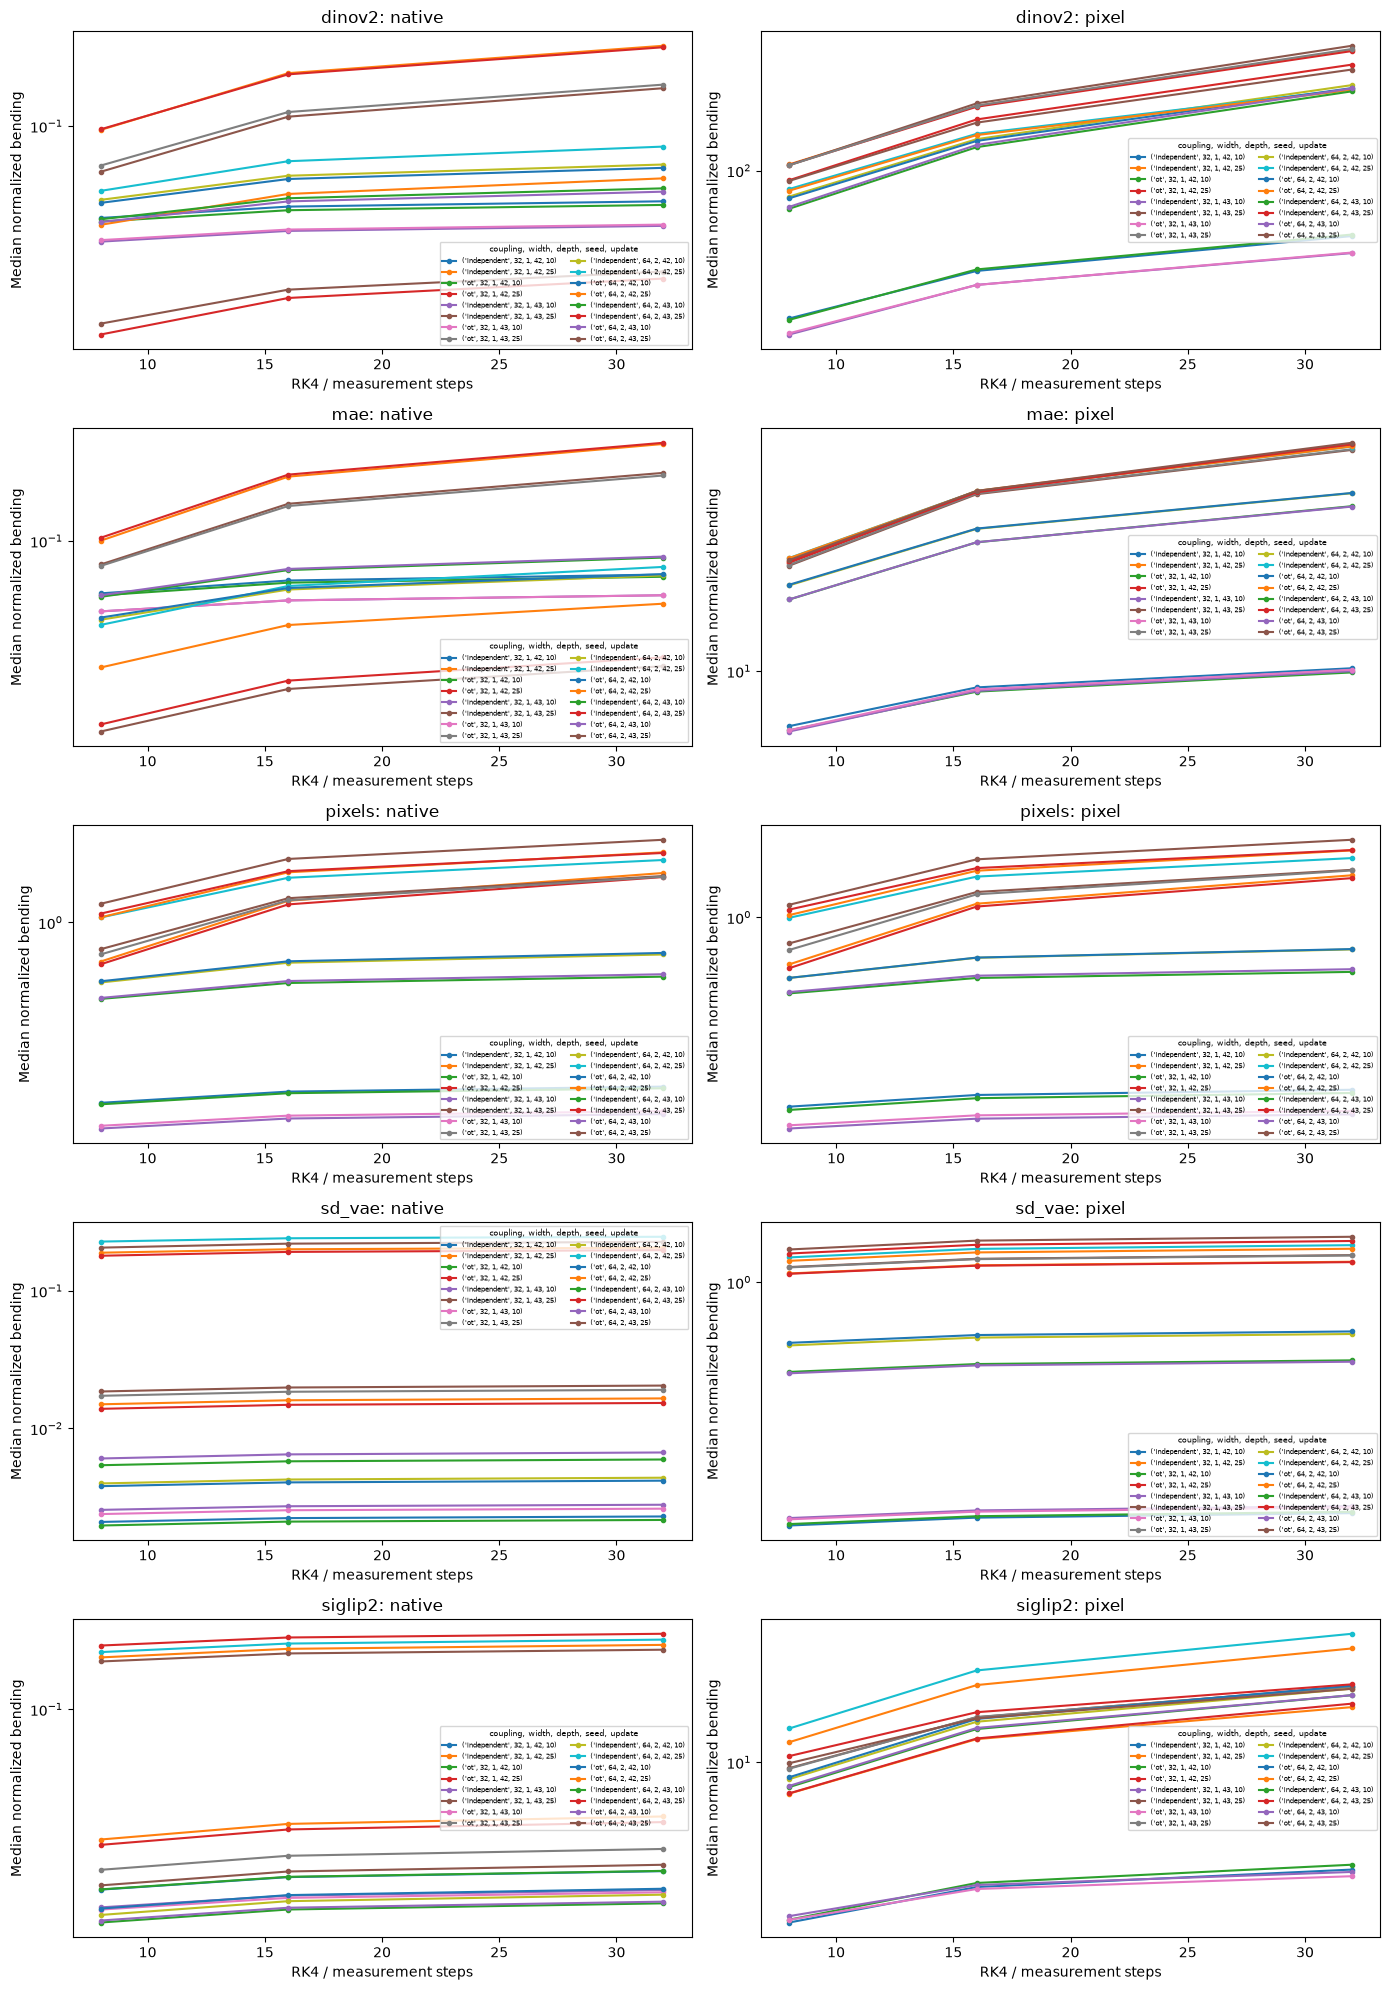

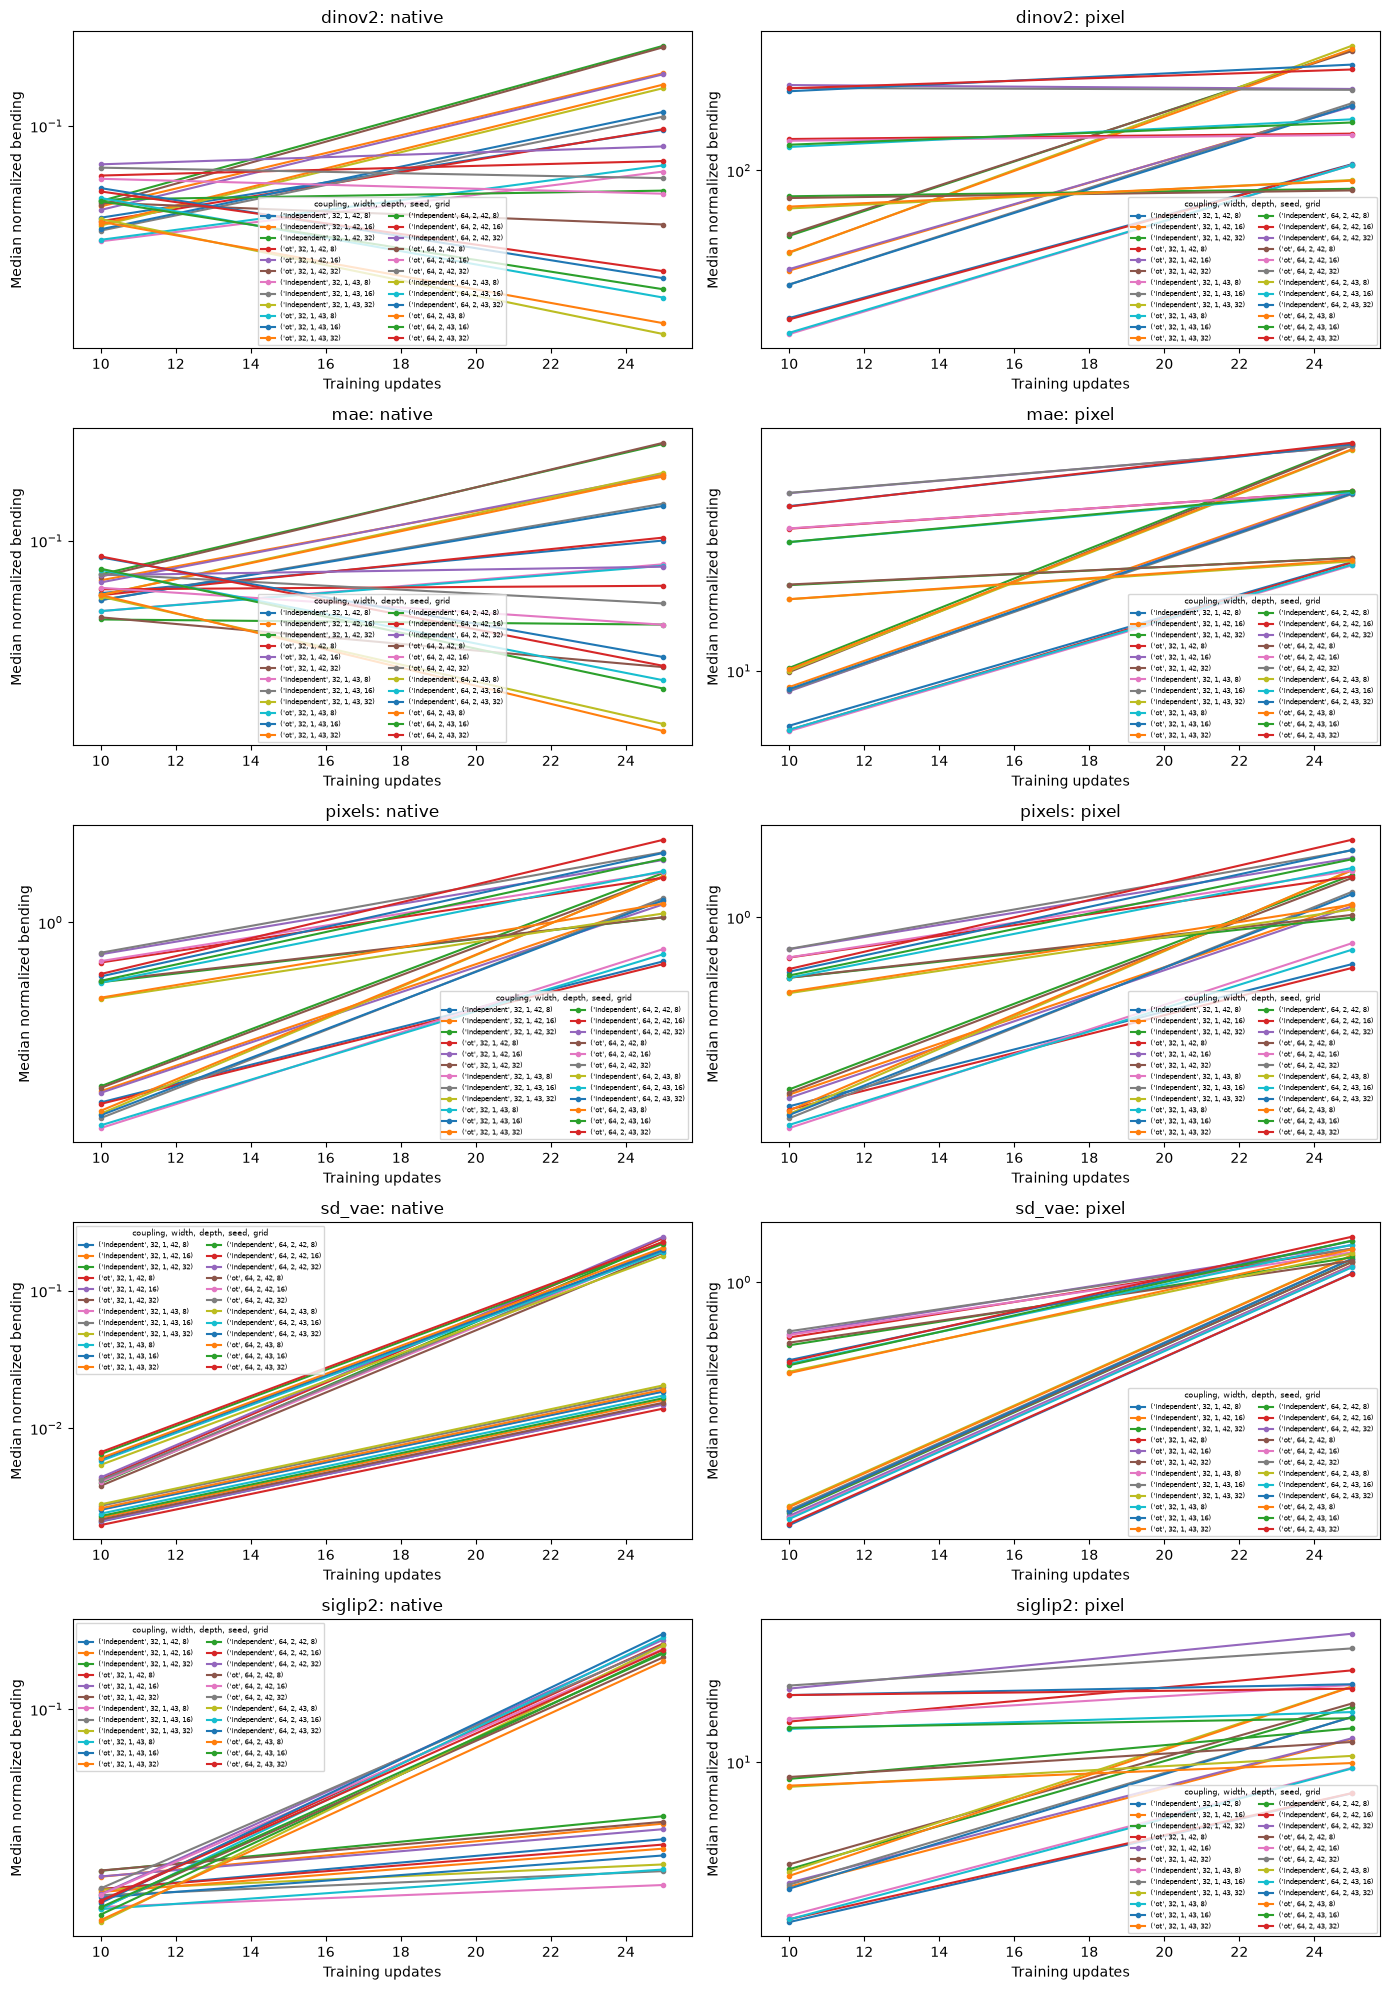

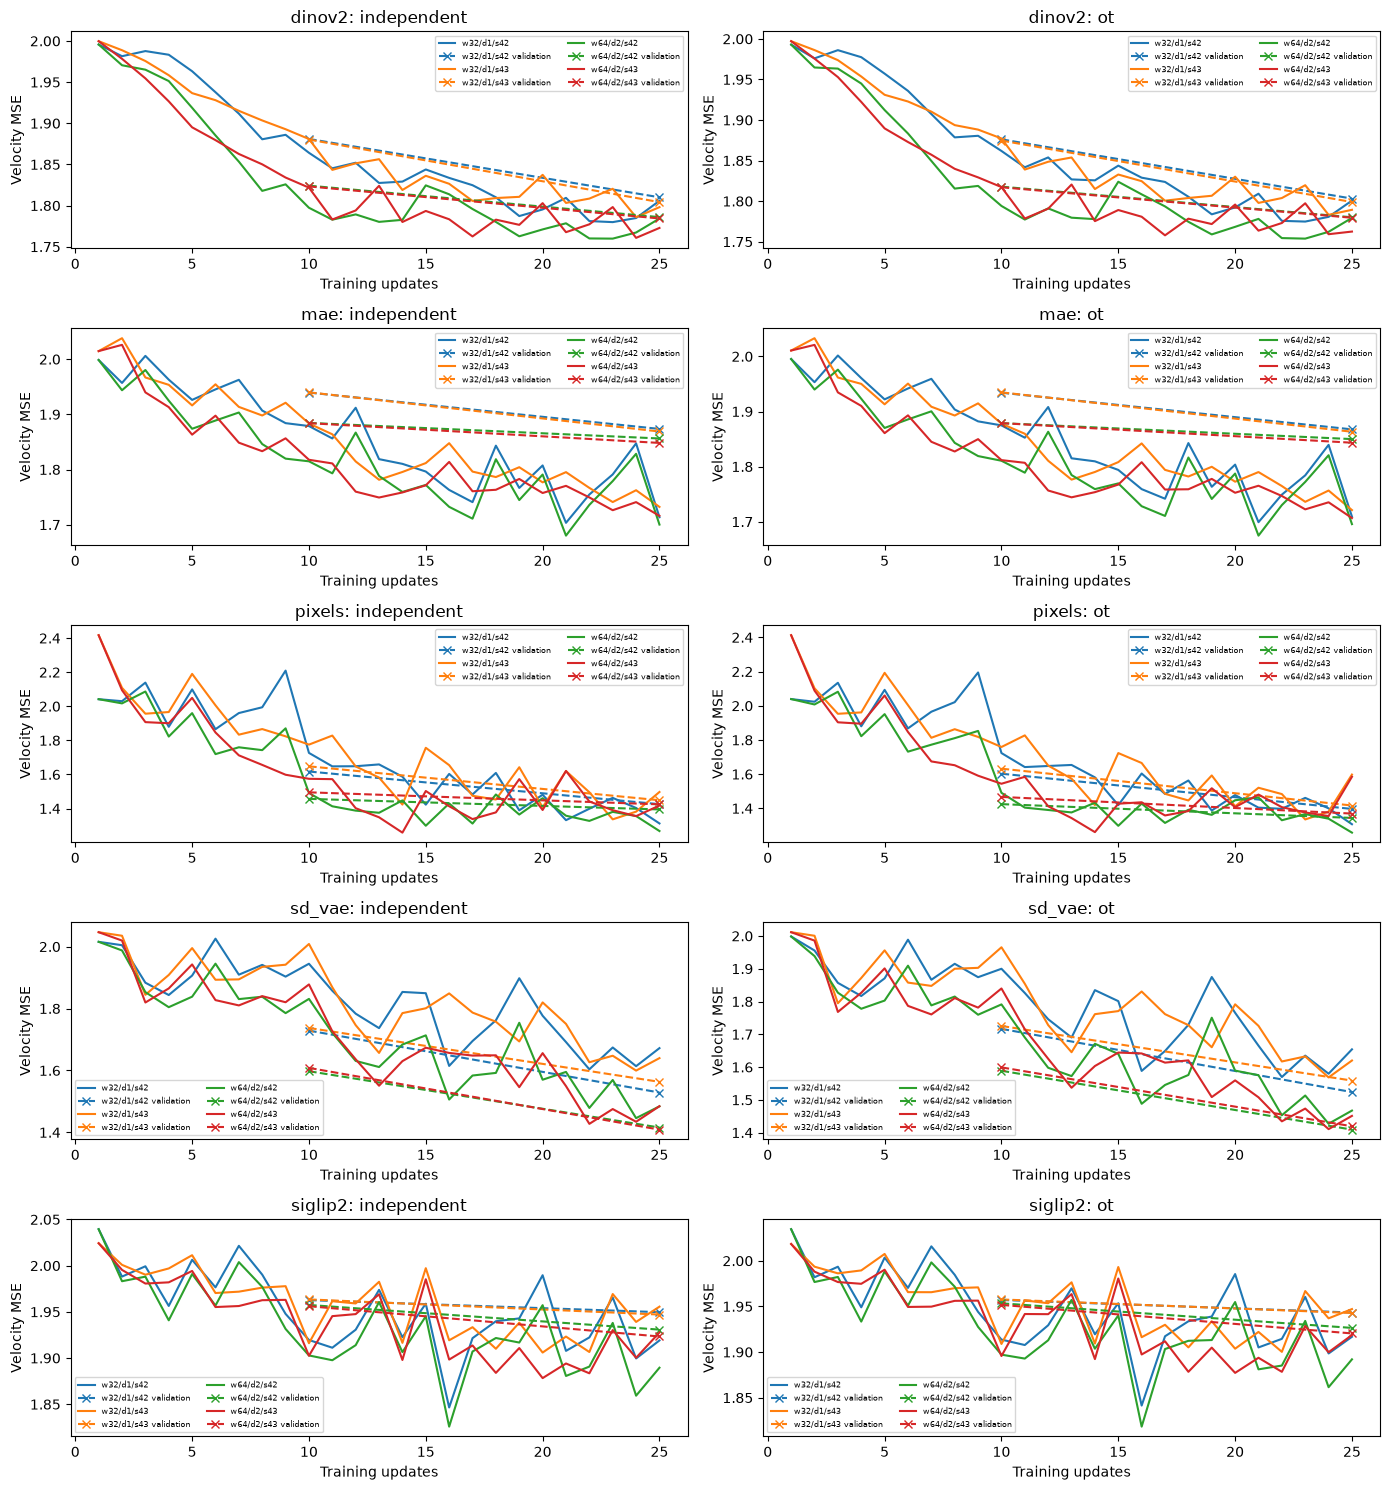

{'native_measurement': {'status': 'unresolved_at_max_grid',
  'successive_changes': [{'bending_energy': {'passed': False,
     'valid_particles': 2,
     'particles': 2,
     'max_absolute_change': 5.4836742419310655e-05,
     'max_relative_change': 0.09277627706734294},
    'normalized_bending': {'passed': False,
     'valid_particles': 2,
     'particles': 2,
     'max_absolute_change': 0.00510584929377407,
     'max_relative_change': 0.09279560645690087},
    'relative_length_excess': {'passed': True,
     'valid_particles': 2,
     'particles': 2,
     'max_absolute_change': 2.6753460408146523e-05,
     'max_relative_change': 0.01300340403832333},
    'stationary_fraction': {'passed': True,
     'valid_particles': 2,
     'particles': 2,
     'max_absolute_change': 0.0,
     'max_relative_change': 0.0}},
   {'bending_energy': {'passed': True,
     'valid_particles': 2,
     'particles': 2,
     'max_absolute_change': 2.7451546680448908e-05,
     'max_relative_change': 0.04463346877

{'8': 4.1077511640223747e-07, '16': 3.590145926304254e-08, '32': 0.0}

{'validation': [{'update': 10, 'loss': 1.8809751272201538}],
 'training_losses': [1.9956973791122437,
  1.981492042541504,
  1.987737774848938,
  1.9832805395126343,
  1.9632524251937866,
  1.9377497434616089,
  1.9117258787155151,
  1.8805912733078003,
  1.8859928846359253,
  1.8641510009765625]}

In [3]:
if rows:
    display(plot_results(rows, 'grid'))
    display(plot_results(rows, 'training'))
    display(plot_losses(rows))
    path = Path(rows[0]['path'])
    detail = json.loads(path.read_text())
    display(detail['grid_checks'], detail['solver_shared_time_rms_errors'])
    display({'validation': detail['validation_history'], 'training_losses': detail['training_loss']})

## Capacity, training-budget interactions, and training-seed replication
Each row summarizes one trained model, not an independent image replication. Two smoke seeds show points/ranges only. Five or more seeds additionally show explicitly exploratory model-seed bootstrap intervals. Validation losses are comparable within an objective, not across independent and OT targets.

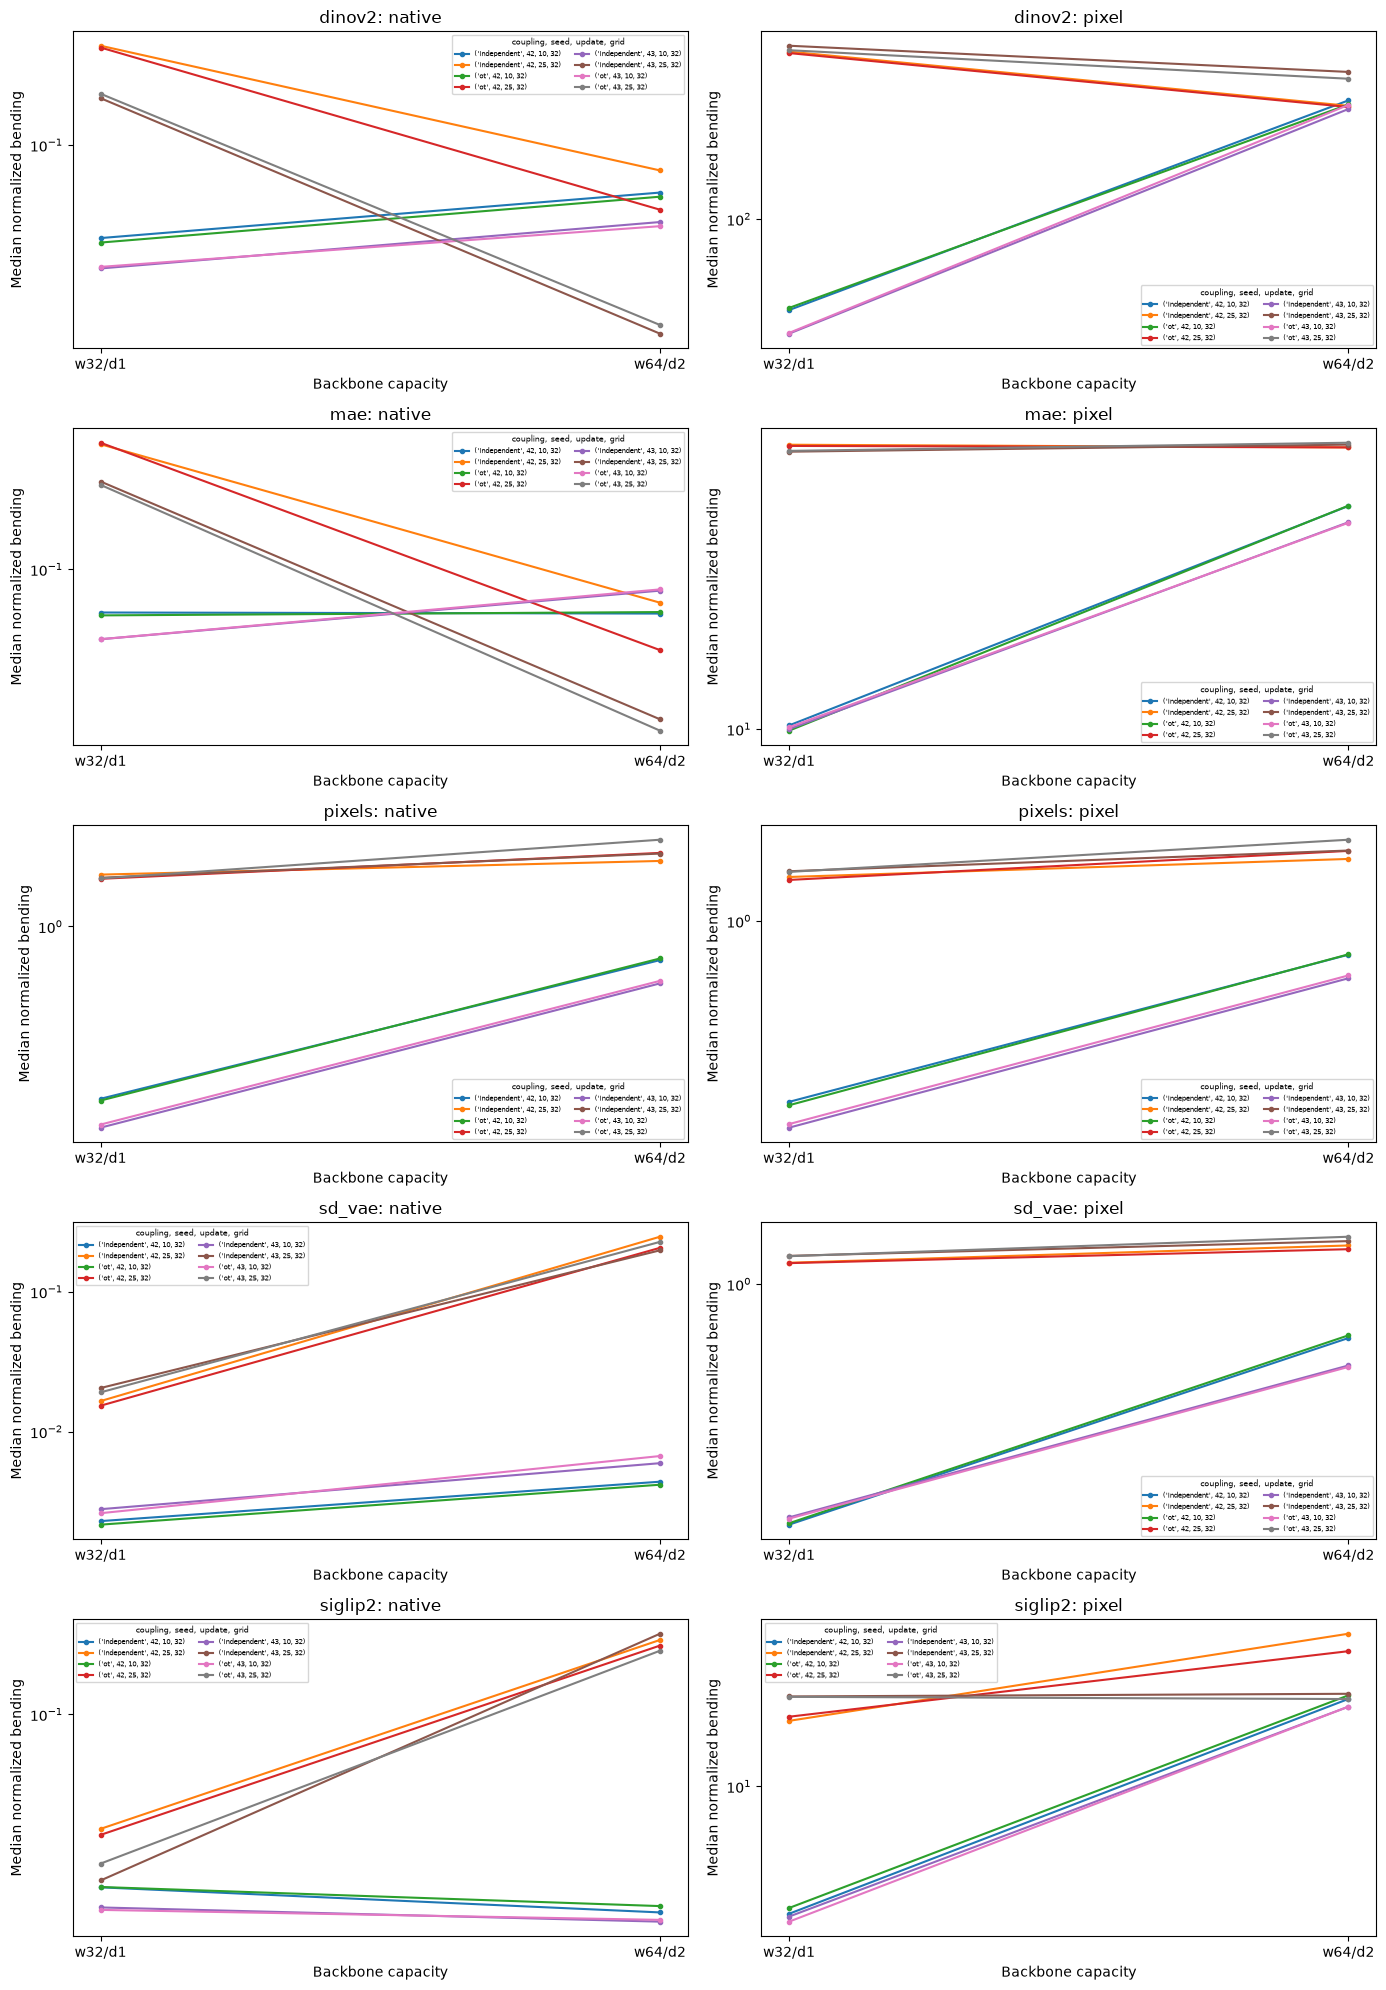

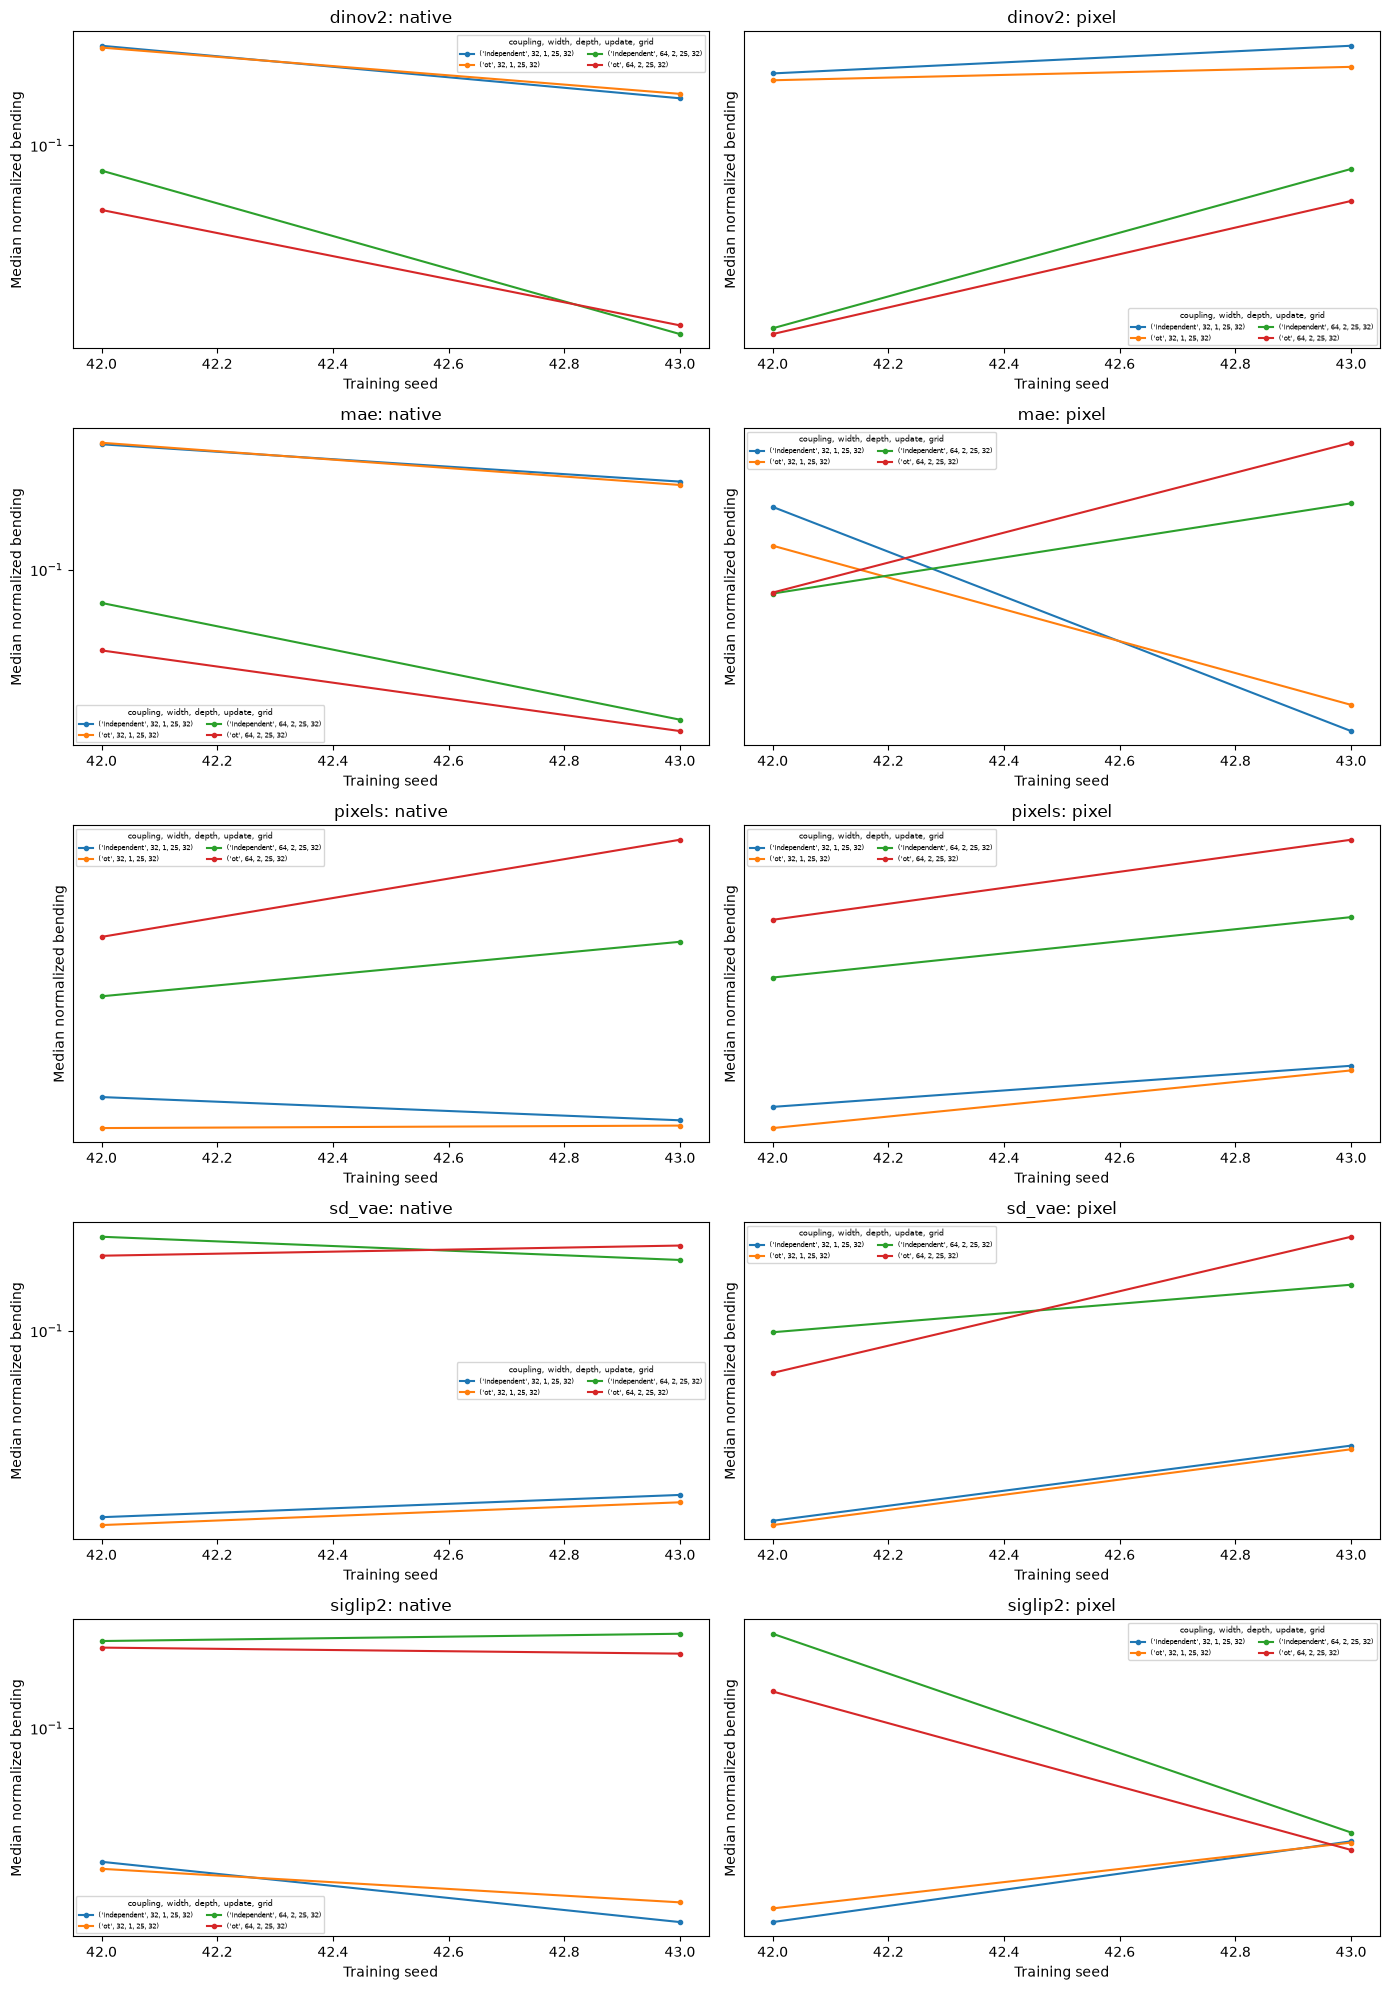

[{'stream_id': 'dinov2-independent-w32-d1-s42',
  'representation': 'dinov2',
  'coupling': 'independent',
  'width': 32,
  'depth': 1,
  'seed': 42,
  'update': 10,
  'grid': 32,
  'space': 'native',
  'normalized_bending': 0.05306939121577567,
  'bending_energy': 0.0005677421799756858,
  'relative_length_excess': 0.0018720898713961986,
  'validation_loss': 1.8809751272201538,
  'endpoint_mmd2': 0.03321545740148624,
  'particles': 2,
  'grid_status': 'unresolved_at_max_grid',
  'path': '/home/srbagchi/Coursework/flow-curvature-diagnostic/results/cifar-sweeps-smoke/dinov2-independent-w32-d1-s42/evaluation-10/summary.json'},
 {'stream_id': 'dinov2-independent-w32-d1-s42',
  'representation': 'dinov2',
  'coupling': 'independent',
  'width': 32,
  'depth': 1,
  'seed': 42,
  'update': 10,
  'grid': 32,
  'space': 'pixel',
  'normalized_bending': 53.081308846119185,
  'bending_energy': 0.6393703119738828,
  'relative_length_excess': 0.47526500123178494,
  'validation_loss': 1.880975127220

[{'representation': 'dinov2',
  'coupling': 'independent',
  'width': 32,
  'depth': 1,
  'update': 10,
  'grid': 32,
  'space': 'native',
  'n_training_seeds': 2,
  'seed_values': [0.05306939121577567, 0.04314078427216521],
  'mean': 0.04810508774397044,
  'minimum': 0.04314078427216521,
  'maximum': 0.05306939121577567,
  'uncertainty_unit': 'trained model seed; particles are not training replications'},
 {'representation': 'dinov2',
  'coupling': 'independent',
  'width': 32,
  'depth': 1,
  'update': 10,
  'grid': 32,
  'space': 'pixel',
  'n_training_seeds': 2,
  'seed_values': [53.081308846119185, 45.04135765759274],
  'mean': 49.06133325185596,
  'minimum': 45.04135765759274,
  'maximum': 53.081308846119185,
  'uncertainty_unit': 'trained model seed; particles are not training replications'},
 {'representation': 'dinov2',
  'coupling': 'independent',
  'width': 32,
  'depth': 1,
  'update': 25,
  'grid': 32,
  'space': 'native',
  'n_training_seeds': 2,
  'seed_values': [0.19692

[{'representation': 'dinov2',
  'width': 32,
  'depth': 1,
  'seed': 42,
  'update': 10,
  'grid': 32,
  'space': 'native',
  'ot_minus_independent': -0.0016027395151191337},
 {'representation': 'dinov2',
  'width': 32,
  'depth': 1,
  'seed': 42,
  'update': 10,
  'grid': 32,
  'space': 'pixel',
  'ot_minus_independent': 0.7987309306048118},
 {'representation': 'dinov2',
  'width': 32,
  'depth': 1,
  'seed': 42,
  'update': 25,
  'grid': 32,
  'space': 'native',
  'ot_minus_independent': -0.0024208258734111365},
 {'representation': 'dinov2',
  'width': 32,
  'depth': 1,
  'seed': 42,
  'update': 25,
  'grid': 32,
  'space': 'pixel',
  'ot_minus_independent': -3.2291491205883744},
 {'representation': 'dinov2',
  'width': 32,
  'depth': 1,
  'seed': 43,
  'update': 10,
  'grid': 32,
  'space': 'native',
  'ot_minus_independent': 0.00046341115901660235},
 {'representation': 'dinov2',
  'width': 32,
  'depth': 1,
  'seed': 43,
  'update': 10,
  'grid': 32,
  'space': 'pixel',
  'ot_minus

{'parameter_count': 73088,
 'patch_features': 768,
 'backbone_width': 32,
 'native_particles': 2,
 'decoded_particles': [0]}

In [4]:
if rows:
    finest = max(r['grid'] for r in rows)
    finest_rows = [r for r in rows if r['grid'] == finest]
    final_rows = [r for r in finest_rows if r['update'] == max(r['update'] for r in finest_rows)]
    display(plot_results(finest_rows, 'capacity'))
    display(plot_results(final_rows, 'seed'))
    display(finest_rows)
    display(seed_summaries(finest_rows))
    display(paired_differences(finest_rows))
    display({k: detail[k] for k in ('parameter_count', 'patch_features', 'backbone_width', 'native_particles', 'decoded_particles')})

## Decoder controls and image quality
Decoded straight-native-path controls isolate decoder-induced bending qualitatively; their curvature is not subtracted as if the components were additive. Endpoint MMD is a small-sample validation discrepancy, not FID. Final test data are reserved until explicit finalist evaluation.

{'bending_energy': {'mean': 0.6462527709097863,
  'median': 0.6462527709097863,
  'p95': 0.6462527709097863,
  'undefined_count': 0},
 'mean_curvature': {'mean': 0.08895526350641479,
  'median': 0.08895526350641479,
  'p95': 0.08895526350641479,
  'undefined_count': 0},
 'acceleration_energy': {'mean': 398564.5471834529,
  'median': 398564.5471834529,
  'p95': 398564.5471834529,
  'undefined_count': 0},
 'path_length': {'mean': 83.05898075140152,
  'median': 83.05898075140152,
  'p95': 83.05898075140152,
  'undefined_count': 0},
 'chord_length': {'mean': 56.27546817365572,
  'median': 56.27546817365572,
  'p95': 56.27546817365572,
  'undefined_count': 0},
 'length_excess': {'mean': 26.783512577745803,
  'median': 26.783512577745803,
  'p95': 26.783512577745803,
  'undefined_count': 0},
 'stationary_fraction': {'mean': 0.0,
  'median': 0.0,
  'p95': 0.0,
  'undefined_count': 0},
 'normalized_bending': {'mean': 53.67709645953583,
  'median': 53.67709645953583,
  'p95': 53.67709645953583,

{'pixel_mmd2_unbiased': 0.03321545740148624,
 'mean_pairwise_rms_distance': 0.22632728452150863,
 'out_of_range_fraction': 0.0009918212890625,
 'note': 'Small-sample pixel discrepancy; negative unbiased MMD2 estimates are valid. Not FID.'}

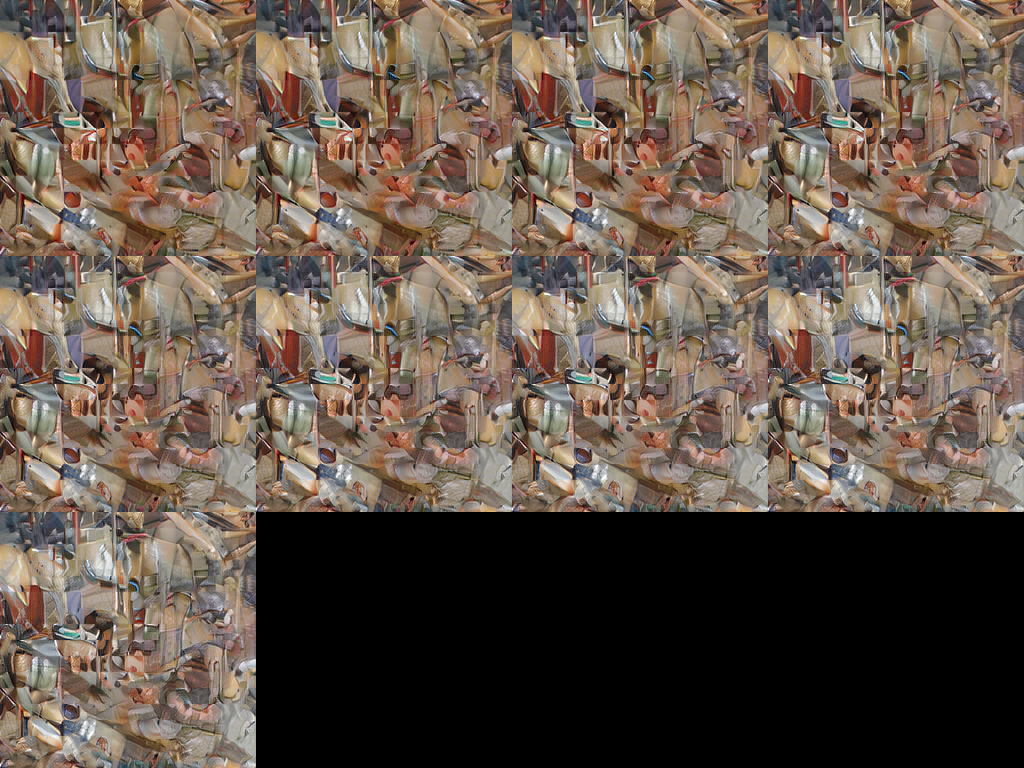

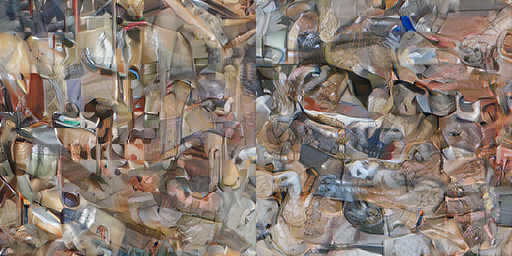

### Legacy pilot — different protocol; not pooled with sweep results

{'seed': 42,
 'n_train': 256,
 'n_eval': 2,
 'image_size': 256,
 'train_steps': 200,
 'integration_steps': 8,
 'batch_size': 8,
 'hidden_width': 64,
 'depth': 2,
 'heads': 4,
 'learning_rate': 0.001,
 'threads': 2,
 'disk_budget_gb': 20,
 'grid_refinement': True,
 'representations': ['dinov2', 'siglip2', 'mae', 'sd_vae', 'pixels']}

'grid_sensitive'

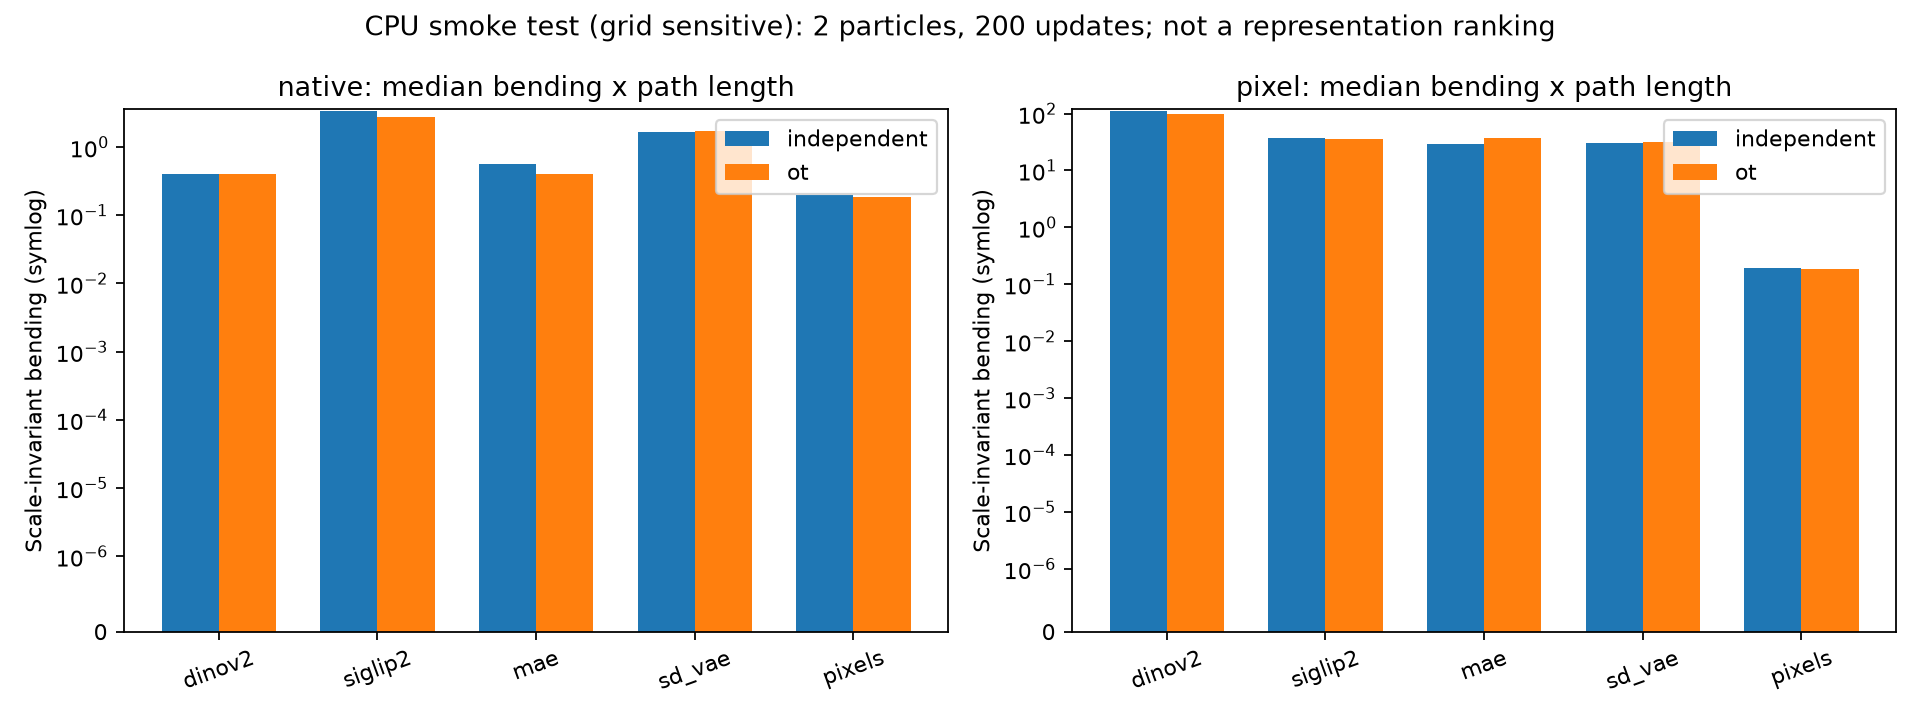

In [5]:
if rows:
    display(detail['control'], detail['endpoint_quality_validation'])
    for filename in ('path.png', 'endpoints.png'):
        image = path.parent / filename
        if image.exists():
            display(Image(filename=str(image)))
if (LEGACY_ROOT / 'summary.json').exists():
    legacy = json.loads((LEGACY_ROOT / 'summary.json').read_text())
    display(Markdown('### Legacy pilot — different protocol; not pooled with sweep results'))
    display(legacy['config'], legacy.get('measurement_status'))
    if (LEGACY_ROOT / 'curvature_comparison.png').exists():
        display(Image(filename=str(LEGACY_ROOT / 'curvature_comparison.png')))

## Runtime and resources
CPU measurements exclude asset downloads. GPU sensitivity scenarios are assumed speedups for accelerable work, not measured A100 performance. Do not equate these with promised runtimes. Rerun the same config on CUDA to replace assumptions with measurements.

In [6]:
runtime_path = RESULT_ROOT / 'runtime.json'
if runtime_path.exists():
    runtime = json.loads(runtime_path.read_text())
    display(runtime)
    display({f"accounted_{runtime['measured_device']}_minutes": runtime['accounted_seconds'] / 60})
else:
    display(Markdown('Runtime report not available yet. Aggregate an executed sweep explicitly.'))
if manifest:
    display(manifest.get('budget'))

{'schema_version': 1,
 'measured_device': 'cpu',
 'hardware': {'platform': 'Linux-6.18.58.1-microsoft-standard-WSL2-x86_64-with-glibc2.39',
  'torch': '2.15.0+cpu',
  'device': 'cpu'},
 'stage_seconds': {'setup': 155.53778366000552,
  'training_validation_serialization': 68.49206265501198,
  'integration': 102.2031284280165,
  'decoding': 9212.605760056002,
  'diagnostics_io': 109.36811350899734},
 'accounted_seconds': 9648.206848308033,
 'per_stream_training': [{'stream': 'dinov2-independent-w32-d1-s42',
   'training_wall_seconds': 1.7416355310015206,
   'timings': {'updates_seconds': 1.6276609710039338,
    'assignment_seconds': 0.04531407700415002,
    'validation_seconds': 0.06818757499786443}},
  {'stream': 'dinov2-ot-w32-d1-s42',
   'training_wall_seconds': 1.808384086998558,
   'timings': {'updates_seconds': 1.670305344981898,
    'assignment_seconds': 0.24347700801081373,
    'validation_seconds': 0.08627227900433354}},
  {'stream': 'dinov2-independent-w32-d1-s43',
   'training

{'accounted_cpu_minutes': 160.80344747180055}

{'retained_bytes': 14941309173,
 'reserved_bytes': 671450368,
 'available_ram_bytes': 11785052160,
 'free_disk_bytes': 900258697216}